# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [32]:
from datetime import datetime, timedelta
import io
import re
import time

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from bs4 import BeautifulSoup

**Create a new datetime object**

In [33]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [34]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [35]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [36]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [37]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [38]:
help(date1.__add__)

Help on method wrapper __add__:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [39]:
documents = [
    "Max likes Sam.",    
    "Sam likes Max.",    
    "Max and Sam.",      
    "Winter likes fall." 
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [40]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [41]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [42]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [43]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [44]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [45]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [46]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

In [47]:
#cleaning the text and counting frequency 
wordLists = [doc.translate(str.maketrans("", "", string.punctuation)).lower().split() for doc in documents]
queryWords = query.translate(str.maketrans("", "", string.punctuation)).lower().split()

#counting how many times term appears in wordList 
docVectors = [[wordList.count(term) for term in voc] for wordList in wordLists]
queryVector = [queryWords.count(term) for term in voc]
print(voc)

for i, vec in enumerate(docVectors):
    print(f"D{i+1}:", vec)
print("Q: ", queryVector)




['and', 'fall', 'likes', 'max', 'sam', 'winter']
D1: [0, 0, 1, 1, 1, 0]
D2: [0, 0, 1, 1, 1, 0]
D3: [1, 0, 0, 1, 1, 0]
D4: [0, 1, 1, 0, 0, 1]
Q:  [0, 0, 1, 0, 1, 1]


In [48]:
#calculating dot product and magnitude for each doc 
import math

dotProducts = [sum(d * q for d, q in zip(vec, queryVector)) for vec in docVectors]
docMagnitudes = [math.sqrt(sum(d ** 2 for d in vec)) for vec in docVectors]
queryMagnitude = math.sqrt(sum(q ** 2 for q in queryVector))

print("Dot products:", dotProducts)
print("Doc magnitudes:", [round(m, 4) for m in docMagnitudes])
print("Query magnitude:", round(queryMagnitude, 4))

Dot products: [2, 2, 1, 2]
Doc magnitudes: [1.7321, 1.7321, 1.7321, 1.7321]
Query magnitude: 1.7321


In [49]:
#computing cosine similiarity 
cosSims = [dotProducts[i] / (docMagnitudes[i] * queryMagnitude) for i in range(len(documents))]

for i in range(len(documents)):
    print(f"D{i+1}: {documents[i]:<20} {round(cosSims[i], 4)}")

D1: Max likes Sam.       0.6667
D2: Sam likes Max.       0.6667
D3: Max and Sam.         0.3333
D4: Winter likes fall.   0.6667


<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [50]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(
    url,
    sep='\t',
    storage_options={'User-Agent': 'WellesleyClassProject/1.0 (in103@wellesley.edu)'}
)

df.head()

,Algeria,DZ,ar.wikipedia,3947,ذكاء_اصطناعي,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,José_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [51]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [52]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

# names of column copied from readme 
columnNames = ["country", "country_code", "project", "page_id", "article", "pageviews"]

df = pd.read_csv(
    url,
    sep='\t',
    header=None,
    names=columnNames,
    storage_options={'User-Agent': 'WellesleyClassProject/1.0 (your_email@wellesley.edu)'}
)

df.head()

print(df.shape)
df.head()

(293466, 6)


,country,country_code,project,page_id,article,pageviews
Algeria,DZ,ar.wikipedia,3947,ذكاء_اصطناعي,Q11660,122
Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
Argentina,AR,es.wikipedia,327209,José_Mourinho,Q79983,114
Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119


In [53]:
#using method of finding classes and sinding titles from there 
with open("Search Results - MyDramaList.html", encoding="utf-8") as file:
    soup = BeautifulSoup(file, "html.parser")

results = soup.find_all("div", class_="box")

for result in results[:8]:
    title_element = result.find("h6", class_="title")
    print(title_element.text.strip() if title_element else None)

100 Days of Deception
Take Charge of My Heart
Doctor X: Mafia in White
Between Steps
Your Personal Taxi
Dive into You
The Scandal
A Love Other than Yours


In [54]:
# skipping boxes without a title and finding rating in each box 
def get_rating(result):
    rating_element = result.find(class_="score")
    if rating_element is not None:
        return float(rating_element.text.strip())
# matching what looks like a rating like 8.1 
    rating_text = result.find(string=lambda text: text and re.fullmatch(r"\s*\d\.\d\s*", text))
    return float(rating_text.strip()) if rating_text else None

#finding all dramas on a page 
def get_search_results(soup):
    shows = []
    for result in soup.find_all("div", class_="box"):
        title_element = result.find("h6", class_="title")
        if title_element is None:          
            continue
        link = title_element.find("a")
        href = link["href"]
        info_element = result.find("span", class_="text-muted")
        info = info_element.text.strip() if info_element else ""
        match = re.search(r"(\d+)\s+episodes?", info)

        shows.append({
            "title": link.text.strip(),
            "url": href if href.startswith("http") else "https://mydramalist.com" + href,
            "info": info,
            "episodes": int(match.group(1)) if match else None,
            "rating": get_rating(result),
        })
    return shows

#checking if it can collect number of shows for the first page 
page_one = get_search_results(soup)
print(f"{len(page_one)} shows on page 1")  
pd.DataFrame(page_one).head()

20 shows on page 1


,title,url,info,episodes,rating
0,100 Days of Deception,https://mydramalist.com/778656-100-days-of-lies,"Korean Drama - 2026, 16 episodes",16,8.1
1,Take Charge of My Heart,https://mydramalist.com/790120-recharge-me,"Korean Drama - 2026, 10 episodes",10,8.3
2,Doctor X: Mafia in White,https://mydramalist.com/787220-doctor-x-age-of...,"Korean Drama - 2026, 12 episodes",12,8.2
3,Between Steps,https://mydramalist.com/802430-love-doctor,"Korean Drama - 2026, 12 episodes",12,8.1
4,Your Personal Taxi,https://mydramalist.com/731727-personal-taxi,"Korean Drama - 2026, 8 episodes",8,7.3


In [55]:
# Looping over all now since page 1 works, looping over saved pages in file instead of website. 
file_names = [
    "Search Results - MyDramaList.html",            
    "Search Results - Page 2 - MyDramaList.html",
    "Search Results - Page 3 - MyDramaList.html",
    "Search Results - Page 4 - MyDramaList.html",
]

all_shows = []
for page_number, file_name in enumerate(file_names, start=1):
    with open(file_name, encoding="utf-8") as file:
        soup = BeautifulSoup(file, "html.parser")

    page_shows = get_search_results(soup)
    for show in page_shows:
        show["page"] = page_number
    print(f"Page {page_number}: {len(page_shows)} shows")
    all_shows.extend(page_shows)
#collecting into a pandas table 
shows_df = pd.DataFrame(all_shows)
print(shows_df.shape)                       # expect (71, 6)
shows_df.sort_values("rating", ascending=False).head(20)

Page 1: 20 shows
Page 2: 20 shows
Page 3: 20 shows
Page 4: 11 shows
(71, 6)


,title,url,info,episodes,rating,page
29,Teach You a Lesson,https://mydramalist.com/778658-get-schooled,"Korean Drama - 2026, 10 episodes",10,9.0,2
10,"Four Hands, Two Sonatas",https://mydramalist.com/795728-four-hands,"Korean Drama - 2026, 12 episodes",12,8.7,1
48,Bloodhounds Season 2,https://mydramalist.com/769141-bloodhounds-sea...,"Korean Drama - 2026, 7 episodes",7,8.7,3
26,Agent Kim Reactivated,https://mydramalist.com/756307-manager-kim,"Korean Drama - 2026, 10 episodes",10,8.6,2
46,Yumi's Cells Season 3,https://mydramalist.com/789724-yumi-s-cells-se...,"Korean Drama - 2026, 8 episodes",8,8.6,3
43,We Are All Trying Here,https://mydramalist.com/790724-everyone-is-fig...,"Korean Drama - 2026, 12 episodes",12,8.5,3
19,A Shop for Killers Season 2,https://mydramalist.com/783100-a-shop-for-kill...,"Korean Drama - 2026, 8 episodes",8,8.5,1
34,The Legend of Kitchen Soldier,https://mydramalist.com/783738-becoming-a-cook...,"Korean Drama - 2026, 12 episodes",12,8.5,2
33,The WONDERfools,https://mydramalist.com/768853-the-b-team,"Korean Drama - 2026, 8 episodes",8,8.5,2
58,In Your Radiant Season,https://mydramalist.com/755669-in-your-brillia...,"Korean Drama - 2026, 12 episodes",12,8.4,3


In [56]:
#manually picking shows amongst the 40 newest based on rating 
picks = pd.DataFrame([
    ("Teach You a Lesson",            9.0, "Teach_You_a_Lesson"),
    ("Four Hands, Two Sonatas",       8.7, "Four_Hands,_Two_Sonatas"),
    ("Agent Kim Reactivated",         8.6, "Agent_Kim_Reactivated"),
    ("A Shop for Killers Season 2",   8.5, "A_Shop_for_Killers"),
    ("The WONDERfools",               8.5, "The_Wonderfools"),
    ("The Legend of Kitchen Soldier", 8.5, "The_Legend_of_Kitchen_Soldier"),
    ("A Bona Fide Killer",            8.4, "A_Bona_Fide_Killer"),
    ("The East Palace",               8.4, "The_East_Palace"),
    ("Flex X Cop Season 2",           8.3, "Flex_X_Cop"),
    ("My Royal Nemesis",              8.3, "My_Royal_Nemesis"),
], columns=["show", "mdl_rating", "article"])
picks

,show,mdl_rating,article
0,Teach You a Lesson,9.0,Teach_You_a_Lesson
1,"Four Hands, Two Sonatas",8.7,"Four_Hands,_Two_Sonatas"
2,Agent Kim Reactivated,8.6,Agent_Kim_Reactivated
3,A Shop for Killers Season 2,8.5,A_Shop_for_Killers
4,The WONDERfools,8.5,The_Wonderfools
5,The Legend of Kitchen Soldier,8.5,The_Legend_of_Kitchen_Soldier
6,A Bona Fide Killer,8.4,A_Bona_Fide_Killer
7,The East Palace,8.4,The_East_Palace
8,Flex X Cop Season 2,8.3,Flex_X_Cop
9,My Royal Nemesis,8.3,My_Royal_Nemesis


In [57]:
# checking that the title exists and saving page id 
wiki_headers = {"User-Agent": "CS 315 Week5 Tasks (in103@wellesley.edu)"}

response = requests.get(
    "https://en.wikipedia.org/w/api.php",
    headers=wiki_headers,
    params={"action": "query", "titles": "|".join(picks["article"]), "format": "json"},
    timeout=10,
)
response.raise_for_status()
pages = response.json()["query"]["pages"]

for page_id, info in pages.items():
    print(f"{page_id:>10}  {info['title']:<35} {'MISSING' if 'missing' in info else 'ok'}")

title_into_id = {
    info["title"].replace(" ", "_"): int(page_id)
    for page_id, info in pages.items()
    if "missing" not in info
}
picks["page_id"] = picks["article"].map(title_into_id)
picks

  83488921  A Bona Fide Killer                  ok
  75697706  A Shop for Killers                  ok
  82003107  Agent Kim Reactivated               ok
  75325345  Flex X Cop                          ok
  82034667  Four Hands, Two Sonatas             ok
  81573431  My Royal Nemesis                    ok
  79560156  Teach You a Lesson                  ok
  79116928  The East Palace                     ok
  81854574  The Legend of Kitchen Soldier       ok
  78258360  The Wonderfools                     ok


,show,mdl_rating,article,page_id
0,Teach You a Lesson,9.0,Teach_You_a_Lesson,79560156
1,"Four Hands, Two Sonatas",8.7,"Four_Hands,_Two_Sonatas",82034667
2,Agent Kim Reactivated,8.6,Agent_Kim_Reactivated,82003107
3,A Shop for Killers Season 2,8.5,A_Shop_for_Killers,75697706
4,The WONDERfools,8.5,The_Wonderfools,78258360
5,The Legend of Kitchen Soldier,8.5,The_Legend_of_Kitchen_Soldier,81854574
6,A Bona Fide Killer,8.4,A_Bona_Fide_Killer,83488921
7,The East Palace,8.4,The_East_Palace,79116928
8,Flex X Cop Season 2,8.3,Flex_X_Cop,75325345
9,My Royal Nemesis,8.3,My_Royal_Nemesis,81573431


In [58]:
#trying one day for September views before looping all days
base = "https://analytics.wikimedia.org/published/datasets/country_project_page/"
#from read me 
columns = ["country", "country_code", "project", "page_id", "article", "wikidata_id", "pageviews"]   

response = requests.get(base + "2026-09-01.tsv", headers=wiki_headers, timeout=120)
response.raise_for_status()
response.encoding = "utf-8" 
day = pd.read_csv(io.StringIO(response.text), sep="\t", header=None, names=columns)

print(day.shape)
print(day.dtypes)
day.head()

(295925, 7)
country           str
country_code      str
project           str
page_id         int64
article           str
wikidata_id       str
pageviews       int64
dtype: object


,country,country_code,project,page_id,article,wikidata_id,pageviews
0,Argentina,AR,es.wikipedia,11526564,La_invitación_(película_de_2026),Q134083296,334
1,Argentina,AR,es.wikipedia,2934940,Víctor_Sarasqueta,Q5671904,131
2,Argentina,AR,es.wikipedia,307495,Sleeping_with_the_Enemy_(película),Q1193347,151
3,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,104
4,Argentina,AR,es.wikipedia,327209,José_Mourinho,Q79983,209


In [59]:
print(day.shape)
print(day.head(3))

print("\nproject values:")
print(day["project"].value_counts().head(5))

print("\nany K-drama-looking titles?")
print(day[day["article"].astype(str).str.contains("Wonderfools|East_Palace|East Palace|Flex", case=False)].head(10))



(295925, 7)
     country country_code       project   page_id  \
0  Argentina           AR  es.wikipedia  11526564   
1  Argentina           AR  es.wikipedia   2934940   
2  Argentina           AR  es.wikipedia    307495   

                              article wikidata_id  pageviews  
0    La_invitación_(película_de_2026)  Q134083296        334  
1                   Víctor_Sarasqueta    Q5671904        131  
2  Sleeping_with_the_Enemy_(película)    Q1193347        151  

project values:
project
en.wikipedia    194410
ja.wikipedia     28420
de.wikipedia     18044
fr.wikipedia     12823
it.wikipedia     10143
Name: count, dtype: int64

any K-drama-looking titles?
             country country_code       project   page_id  \
1369   United States           US  en.wikipedia    768604   
8706   United States           US  en.wikipedia  74734159   
12138          India           IN  en.wikipedia  79116928   
26931          India           IN  en.wikipedia  78258360   
33532  United States   

In [60]:
#checking header line of file 
print((day["country"] == "country").sum(), "header-looking rows")

#checking how wikipedia project is written 
print(day["project"].value_counts().head(8))

# how are titles written checking 
print(day["article"].head(10).tolist())

0 header-looking rows
project
en.wikipedia    194410
ja.wikipedia     28420
de.wikipedia     18044
fr.wikipedia     12823
it.wikipedia     10143
es.wikipedia     10088
zh.wikipedia      5323
pt.wikipedia      3497
Name: count, dtype: int64
['La_invitación_(película_de_2026)', 'Víctor_Sarasqueta', 'Sleeping_with_the_Enemy_(película)', 'Juana_Viale', 'José_Mourinho', 'Los_Angeles_Galaxy', 'Copa_Libertadores_de_América', 'Michael_Jackson', 'Alexis_Mac_Allister', 'El_Polaco']


In [61]:
# matching Wikipedia trial 
en = day[day["project"].astype(str).str.startswith("en.wikipedia")]

titles_with_spaces = picks["article"].str.replace("_", " ")
print("Try A - titles with spaces:     ", en["article"].isin(titles_with_spaces).sum(), "rows")
print("Try B - titles with underscores:", en["article"].isin(picks["article"]).sum(), "rows")
print("Try C - page_id:                ",
      pd.to_numeric(en["page_id"], errors="coerce").isin(picks["page_id"]).sum(), "rows")


Try A - titles with spaces:      0 rows
Try B - titles with underscores: 59 rows
Try C - page_id:                 59 rows


In [62]:
# one function for each day with a loop over September 
def load_day(date):
    url = base + date.strftime("%Y-%m-%d") + ".tsv"
    try:
        response = requests.get(url, headers=wiki_headers, timeout=120)
        response.raise_for_status()
    except requests.exceptions.HTTPError as error:
        print(f"{date:%Y-%m-%d}: skipped ({error})")
        return None

    #reading into pandas 

    day = pd.read_csv(
        io.StringIO(response.text), sep="\t", header=None, names=COLUMNS,
        keep_default_na=False, na_values=[""],          
    )
    day = day[day["country"] != "country"]             
    day = day[day["project"].astype(str).str.startswith("en.wikipedia")].copy()
    day["article"] = day["article"].astype(str).str.replace(" ", "_")
    day["page_id"] = pd.to_numeric(day["page_id"], errors="coerce")
    day["pageviews"] = pd.to_numeric(day["pageviews"], errors="coerce")

    keep = day["article"].isin(picks["article"]) | day["page_id"].isin(picks["page_id"].dropna())
    day = day[keep].copy()
    day["date"] = date
    return day


days = []
for date in pd.date_range("2026-09-01", "2026-09-30"):
    result = load_day(date)
    if result is not None:
        print(f"{date:%Y-%m-%d}: {len(result)} matching rows")
        days.append(result)
    time.sleep(1)

sept = pd.concat(days, ignore_index=True)

# label every row with its show, title and page id backup 
article_to_show = dict(zip(picks["article"], picks["show"]))
id_to_show = dict(zip(picks["page_id"].dropna(), picks["show"]))
sept["show"] = sept["article"].map(article_to_show).fillna(sept["page_id"].map(id_to_show))
sept.head()

NameError: name 'COLUMNS' is not defined

In [ ]:
# csv file with totals for sept 2026 with file and country 
by_show_country = (
    sept.groupby(["show", "article", "country", "country_code"], as_index=False, dropna=False)["pageviews"].sum()
        .merge(picks[["show", "mdl_rating"]], on="show")
        .sort_values(["show", "pageviews"], ascending=[True, False])
)
by_show_country.to_csv("kdrama_pageviews_september_2026.csv", index=False)
print(by_show_country.shape)
by_show_country.head(15)

(92, 6)


,show,article,country,country_code,pageviews,mdl_rating
9,A Bona Fide Killer,A_Bona_Fide_Killer,Philippines,PH,14200,8.4
13,A Bona Fide Killer,A_Bona_Fide_Killer,United States,US,13429,8.4
7,A Bona Fide Killer,A_Bona_Fide_Killer,Malaysia,MY,8084,8.4
4,A Bona Fide Killer,A_Bona_Fide_Killer,India,IN,7294,8.4
10,A Bona Fide Killer,A_Bona_Fide_Killer,Singapore,SG,5610,8.4
5,A Bona Fide Killer,A_Bona_Fide_Killer,Indonesia,ID,4205,8.4
1,A Bona Fide Killer,A_Bona_Fide_Killer,Canada,CA,2154,8.4
0,A Bona Fide Killer,A_Bona_Fide_Killer,Australia,AU,1435,8.4
12,A Bona Fide Killer,A_Bona_Fide_Killer,United Kingdom,GB,1084,8.4
8,A Bona Fide Killer,A_Bona_Fide_Killer,Nigeria,NG,857,8.4


18 countries in total; the chart shows the top 20
Top 20 = 100% of all views


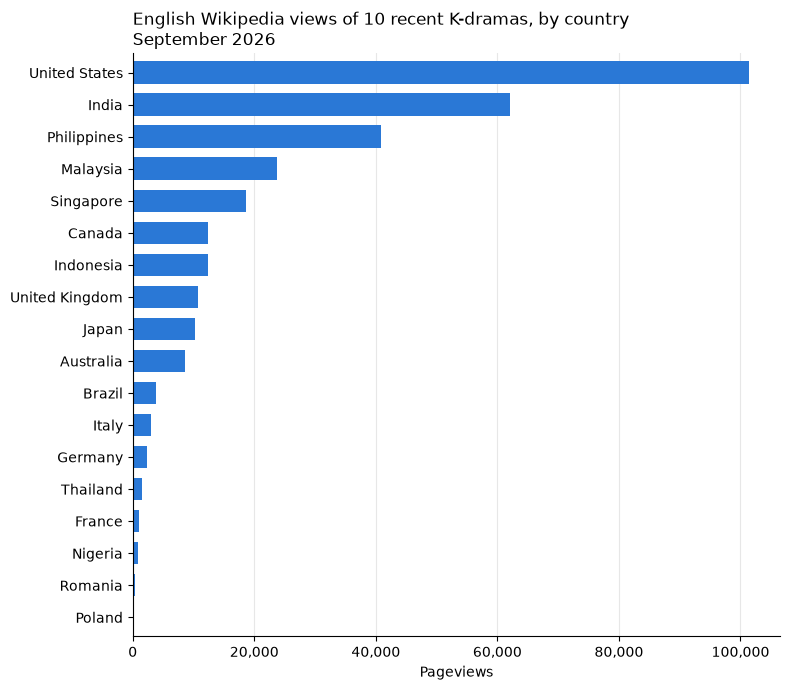

In [ ]:
# views by country 
by_country = sept.groupby("country")["pageviews"].sum().sort_values(ascending=False)
top20 = by_country.head(20).sort_values()           
ax = top20.plot.barh(figsize=(8, 7), color="#2a78d6", width=0.7)
ax.set_title("English Wikipedia views of 10 recent K-dramas, by country\nSeptember 2026", loc="left")
ax.set_xlabel("Pageviews")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("views_by_country.png", dpi=150)
plt.show()

show
Four Hands, Two Sonatas          90232
A Bona Fide Killer               60460
Agent Kim Reactivated            45815
Teach You a Lesson               43228
Flex X Cop Season 2              20494
A Shop for Killers Season 2      18133
The WONDERfools                  13836
The East Palace                  12167
My Royal Nemesis                  6312
The Legend of Kitchen Soldier     3870
Name: pageviews, dtype: int64


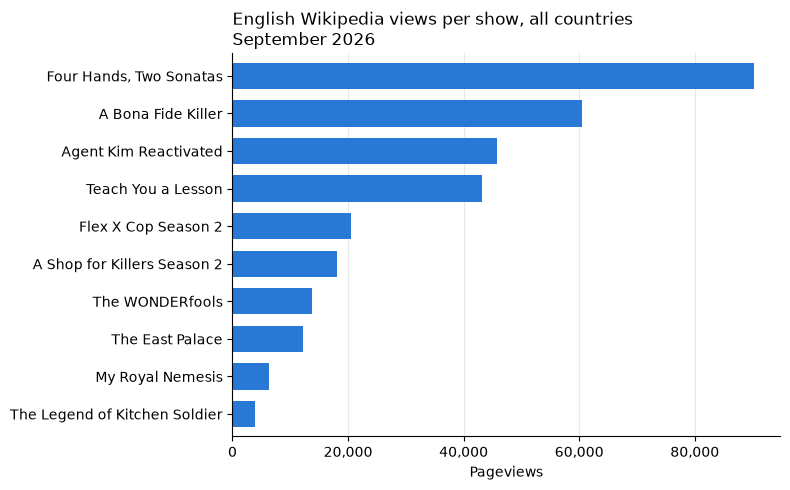

In [ ]:
#views by show
by_show = sept.groupby("show")["pageviews"].sum().sort_values()
print(by_show.sort_values(ascending=False))

ax = by_show.plot.barh(figsize=(8, 5), color="#2a78d6", width=0.7)
ax.set_title("English Wikipedia views per show, all countries\nSeptember 2026", loc="left")
ax.set_xlabel("Pageviews")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("views_by_show.png", dpi=150)
plt.show()

## Qualitative Question 

I don't think I have enough information to qualitatively or quantitatively answer this question, but I a correlation is harder to see with what I have right now as I only picked the top rated shows. To guess, I would probably say no, because a show can just be popular which makes everyone want to watch it, but it does not necessarily have to be good or have good ratings. Some really popular shows are also just rated badly. But this would be good to answer if we did have enough information to answer it.  